# Penrose medallion

Penrose rhombi cover the plane in a pattern that never repeats. One way to grow them: start with
ten triangles around a point, then cut every triangle into smaller ones, splitting edges by the
golden ratio. This is called deflation. The triangles pair up into thin and thick rhombi, and
after six rounds the rhombi are about 20 px across: thin ones in deep teal, thick ones lighter,
with gold edges.

In [1]:
import cmath
import math

from nbturtle import render

W = H = 800
PHI = (1 + 5 ** 0.5) / 2
DEPTH = 6
RADIUS = 390
INK = "#0f0f14"
THIN = "#15454d"
THICK = "#2a6b73"
GOLD = "#c9a24a"

## Ten triangles around a point

Points are complex numbers, which makes turning easy: `cmath.rect(1, angle)` is the point at
distance 1 in that direction. A triangle is `(kind, a, b, c)`, kind 0 for halves of thin rhombi
and 1 for halves of thick ones. Every other triangle swaps `b` and `c`, so neighbours are mirror
images.

In [2]:
def start():
    tris = []
    for i in range(10):
        b = cmath.rect(1, (2 * i - 1) * math.pi / 10)
        c = cmath.rect(1, (2 * i + 1) * math.pi / 10)
        if i % 2 == 0:
            b, c = c, b
        tris.append((0, 0j, b, c))
    return tris

## Deflation

`subdivide` replaces each triangle with two or three smaller ones. `a + (b - a) / PHI` is the
point that splits the edge from `a` to `b` in the golden ratio.

In [3]:
def subdivide(tris):
    out = []
    for kind, a, b, c in tris:
        if kind == 0:
            p = a + (b - a) / PHI
            out += [(0, c, p, b), (1, p, c, a)]
        else:
            q = b + (a - b) / PHI
            r = b + (c - b) / PHI
            out += [(1, r, c, a), (0, q, r, b), (1, r, q, a)]
    return out

## Drawing rhombi

Each triangle is filled, then two of its edges are drawn in gold. The third edge, `b` to `c`, is
the diagonal it shares with its partner, so leaving it out shows rhombi instead of triangles.
Rounds 0 to 3:

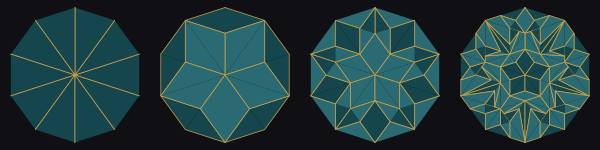

In [4]:
def rhombi(t, tris, radius, cx=0):
    t.pensize(1)
    for kind, a, b, c in tris:
        pa, pb, pc = [(cx + z.real * radius, z.imag * radius) for z in (a, b, c)]
        t.fillcolor(THIN if kind == 0 else THICK)
        t.goto(pa)
        t.begin_fill()
        t.goto(pb)
        t.goto(pc)
        t.goto(pa)
        t.end_fill()
        # rhombus edges meet at a; the edge b-c is the rhombus diagonal and stays hidden
        t.pencolor(GOLD)
        t.goto(pc)
        t.pendown()
        t.goto(pa)
        t.goto(pb)
        t.penup()


def rounds(t):
    tris = start()
    for k in range(4):
        rhombi(t, tris, 90, -300 + k * 200)
        tris = subdivide(tris)


render(rounds, 800, 200, INK, dpi=54)

## Six rounds

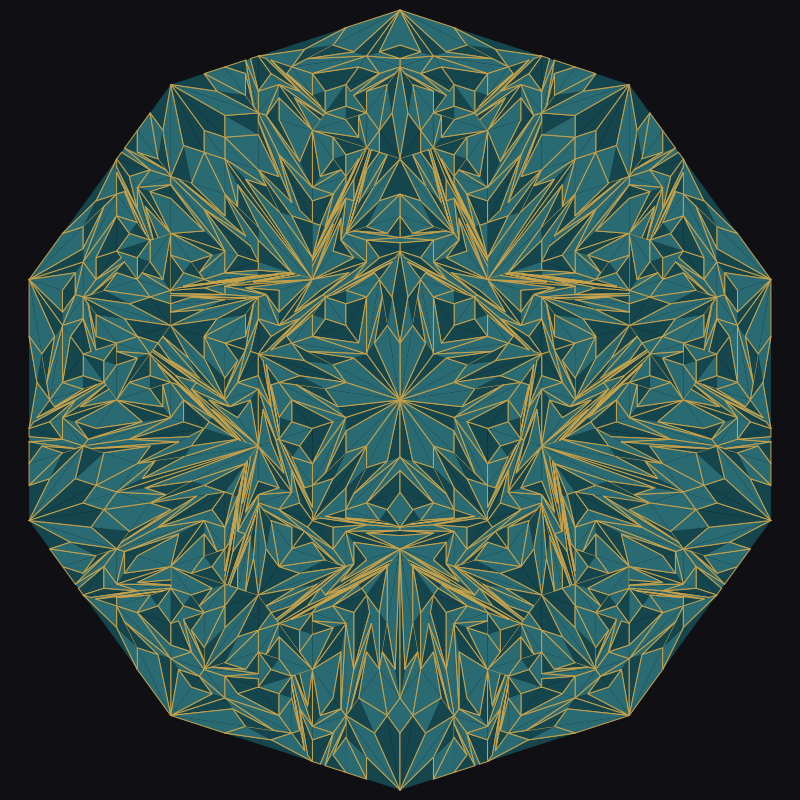

In [5]:
def draw(t):
    tris = start()
    for _ in range(DEPTH):
        tris = subdivide(tris)
    rhombi(t, tris, RADIUS)


canvas = render(draw, W, H, INK)
canvas

## As a fabric

This one is a block repeat: the medallion sits on plain ink, so the fabric is a grid of
medallions.

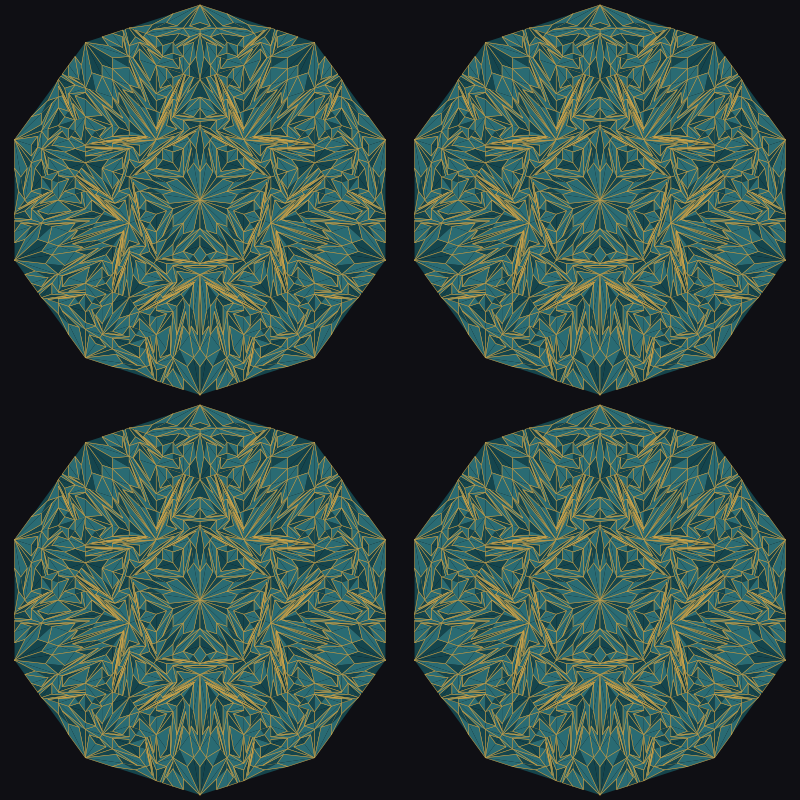

In [6]:
canvas.repeat()

## Try

- `DEPTH = 8` for much finer rhombi.
- Color by distance from the center as well as by kind, using `abs(a)`.